# Урок 16. Сколько камер нужно одному пятну

[План курса](../../README_ru.md)

На первом снимке два оранжевых пятна выглядят одинаково. Одно маленькое и близкое, другое крупнее и дальше. Ошибка на фотографии почти нулевая в обоих случаях. Камера немного отъезжает в сторону, и одно пятно съезжает с образца. Это смещение даст обучению информацию о глубине.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo

## Два снимка для обучения, третий для проверки

Левый кадр принадлежит фиксированному образцу на глубине 4, правый строится из текущей сцены. Позиции камер известны заранее. Камера A стоит при X = 0, B — при +0.8, проверочная — при −0.6. Они смотрят параллельно. Переключатель обучения определяет, какие изображения входят в ошибку. Камера для просмотра выбирает только картинку на экране.

При старте глубина модели равна 2.4. У камеры A изображения совпадают ещё до первого шага. У B различие заметно. После двадцати шагов на двух кадрах становится лучше и на третьем, хотя обновления ни разу не использовали его пиксели.

In [2]:
display(demo.experiment(16, "ru"))

## Семейство одинаковых первых кадров

Обозначим неизвестную глубину $z>0$ в единицах мира. Центр модели — $(0.10z,-0.05z,z)$, её три масштаба — $(0.12z,0.08z,0.06z)$. Мы намеренно связали шесть чисел одним параметром. Увеличение $z$ вдвое увеличивает и расстояние, и размер вдвое. Цвет $(0.85,0.20,0.08)$ и непрозрачность $0.9$ закреплены. Камера A смотрит вдоль $+Z$, фокус $f=28$ пикселей, центр кадра $33\times33$ лежит в $(16,16)$.

Горизонтальная координата $u_A=16+28\cdot0.10z/z=18.8$, вертикальная $v_A=16+28\cdot(-0.05)z/z=14.6$. Оба $z$ в дроби сократились. Масштаб по горизонтали тоже содержит отношение $0.12z/z$. Даже поправка из-за протяжённости вдоль глубины не ломает совпадение: все элементы якобиана уменьшаются как $1/z$, а пространственная ковариация растёт как $z^2$. В произведении $J\Sigma J^\mathsf{T}$ два деления на $z$ гасят этот квадрат. Поэтому совпадает **весь след**, включая яркость по краям.

Для $z=2.4$ центр $X=0.24$ и горизонтальный масштаб $0.288$. Для $z=4$ это $0.40$ и $0.48$. Камера A не различает эти сцены при сколь угодно точной оптимизации.

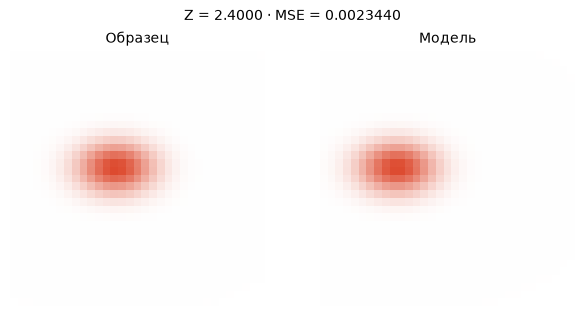

In [3]:
fig = demo.ray_figure("ru")
display(fig)
plt.close(fig)

## Параллакс можно посчитать до обучения

Если камера B перенесена вправо на $b=0.8$, координата точки в ней $X-b$. Подстановка в перспективу даёт

$$
u_B=16+28(0.10z-b)/z=18.8-28b/z.
$$

У ближней модели $u_B=18.8-22.4/2.4\approx9.467$, у образца $18.8-22.4/4=13.2$. Сдвиг между снимками называют параллаксом. Для образца $u_A-u_B=5.6$ пикселя. Из $u_A-u_B=fb/z$ можно восстановить глубину, когда известны $f,b$ и соответствующие центры: $z=28\cdot0.8/5.6=4$. В настоящей паре изображений сначала пришлось бы выяснить, какие пиксели соответствуют одной точке. У гауссиан вообще нет жёсткого края. Поэтому в опыте сравниваются все пиксели двух кадров.

In [4]:
for z in [2.4, 4.0, 7.0]:
    model = sr.ray_scene(z)
    for baseline in (0, .8, -.6):
        cam = sr.translated_camera(baseline)
        uv = sr.project_splats(model, cam, 33, 33)[0]["mean"]
        print(f"Z={z:g}, Xcam={baseline:+g}: u={uv[0]:.3f}, MSE={sr.ray_loss(z,(baseline,)):.8f}")

Z=2.4, Xcam=+0: u=18.800, MSE=0.00000000
Z=2.4, Xcam=+0.8: u=9.467, MSE=0.00468808
Z=2.4, Xcam=-0.6: u=25.800, MSE=0.00277686
Z=4, Xcam=+0: u=18.800, MSE=0.00000000
Z=4, Xcam=+0.8: u=13.200, MSE=0.00000000
Z=4, Xcam=-0.6: u=23.000, MSE=0.00000000
Z=7, Xcam=+0: u=18.800, MSE=0.00000000
Z=7, Xcam=+0.8: u=15.600, MSE=0.00211890
Z=7, Xcam=-0.6: u=21.200, MSE=0.00121875


## Один настоящий шаг по ошибке

Пусть $L_A,L_B$ — средние квадраты разностей RGB из урока 6. Для одного вида знаменатель $33\cdot33\cdot3=3267$ чисел. В начале $L_A$ равна нулю с точностью вычислений, $L_B\approx0.00468808$. Берём одинаковый вес для камер: $L=(L_A+L_B)/2\approx0.00234404$. Отложенный снимок в эту сумму не входит.

Есть только одно неизвестное число $z$. Для проверки производной строим два соседних варианта, $z-h$ и $z+h$, где $h=0.002$ единицы мира. Знаменатель при вычислении наклона — расстояние между этими вариантами, $2h=0.004$.

$$
\begin{aligned}
g &\approx \frac{L(2.402)-L(2.398)}{0.004}\\
  &\approx (0.0023357144-0.0023523820)/0.004=-0.004167.
\end{aligned}
$$

Минус говорит, что небольшое увеличение глубины здесь уменьшает ошибку. При размере шага $\eta=80$ получим $z_{\rm new}=2.4-80(-0.004167)\approx2.73335$. Размер шага переводит наклон в сдвиг глубины; число 80 относится к этой шкале ошибки. Для защиты от ухода за камеру глубина ограничена интервалом от 1.25 до 7. После двадцати таких шагов $z\approx3.8101$. Проверочная ошибка снижается с $0.00277686$ до $0.00001703$. При обучении только на A график практически плоский.

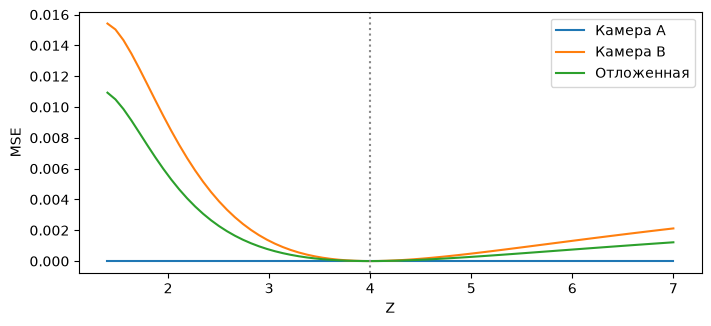

In [5]:
fig = demo.ray_landscape("ru")
display(fig)
plt.close(fig)

In [6]:
z = 2.4
for step in range(20):
    z, gradient = sr.depth_step(z, (0,.8))
print(round(z, 6), sr.ray_loss(z, (0,.8)), sr.ray_loss(z, (-.6,)))
assert sr.ray_loss(z, (-.6,)) < sr.ray_loss(2.4, (-.6,))

3.810089 1.5238536519958356e-05 1.70260316191234e-05


## Из одного параметра — в сцену из двух гауссиан

Теперь отвяжем положение от ширины. В отдельном опыте два пятна имеют собственные центры и RGB, шесть чисел на каждое. Масштабы, повороты, непрозрачности и калибровка камер известны. На входе две цветные картинки с камер при $X=-0.8$ и $+0.65$. Третья камера при $+0.12$ даёт проверочный ракурс. Из неё построены все три картинки ниже.

Программа строит проекции, смешивает пятна и усредняет ошибки **только первых двух** кадров. В PyTorch цвет и центр остаются связанными со значениями пикселей вычислительной цепочкой. Вызов `backward()` возвращает для каждого из 12 чисел скорость изменения общего loss, как в уроке 8. Здесь шаги подбирает Adam. Он помнит среднее направление и средний квадрат прошлых градиентов для каждого числа, чтобы подстраивать длину его шага. Индексы отсортированных слоёв фиксированы на отдельном шаге; в точке перестановки порядок дискретен. После обновления RGB ограничен от 0 до 1, глубина от 1.25 до 7.

Обучение начинается с неточных центров и приглушённых цветов. За 45 шагов проверочная MSE падает примерно с $0.002427$ до $0.00000827$. Низкая ошибка на ещё одной картинке проверяет предсказание в этом ракурсе. У невидимых сторон и заслонённых деталей по-прежнему нет измерений.

In [7]:
import torch
from splat_fit import train_two_splats
torch.set_num_threads(1)
run = train_two_splats(45)
print(np.array(run["history"])[[0, 15, 45]])
assert run["history"][-1][1] < run["history"][0][1] / 100

[[2.35787013e-03 2.42663412e-03]
 [1.26140177e-04 1.16656163e-04]
 [9.42653280e-06 8.26944021e-06]]


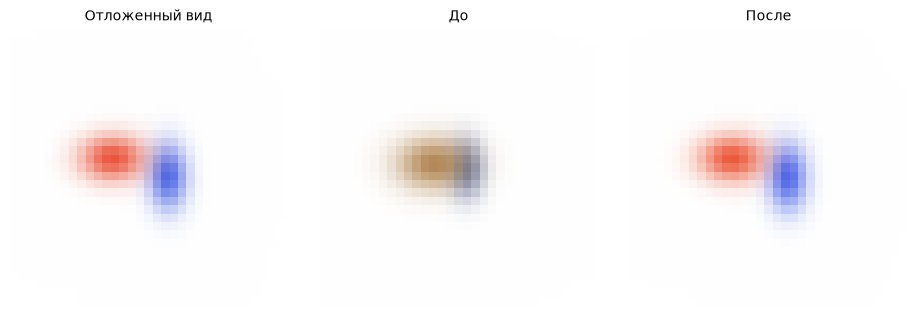

In [8]:
fig = demo.panel([run["target"],run["before"],run["after"]], ["Отложенный вид","До","После"])
display(fig)
plt.close(fig)

## Опыты и разбор

Поможет ли вторая фотография из той же точки, если первая уже совпала? Что станет с различимостью глубин при совсем маленьком смещении камеры?

<details><summary>Разбор</summary>

Вторая копия A удвоит число измерений и знаменатель среднего, но оставит ту же плоскую зависимость от глубины. При $b=0.008$ вместо $0.8$ разность центров между гипотезами 2.4 и 4 составит всего $3.733/100\approx0.037$ пикселя. Теоретическая разница есть; на реальных снимках её легче потерять из-за шума, смаза и ошибки позы.

</details>